In [ ]:
import os
import glob
import random
from typing import Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import timm
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform

import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
import torchmetrics

print(f"PyTorch: {torch.__version__}")
print(f"Lightning: {pl.__version__}")
print(f"TIMM: {timm.__version__}")
print(f"Device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

c:\Users\Liuluotu\Anaconda\anaconda3\envs\flower_classification\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
PATH_DATA = './data'
PATH_TRAIN_CSV = os.path.join(PATH_DATA, 'train.csv')
PATH_TRAIN_IMG = os.path.join(PATH_DATA, 'train')
PATH_TEST_IMG = os.path.join(PATH_DATA, 'test')

df = pd.read_csv(PATH_TRAIN_CSV)
df_wide_target = df.pivot(index='image_path', columns='target_name', values='target').reset_index()

other_features = df.drop(columns=['target_name', 'target']).drop_duplicates(
    subset='image_path',  # 按image_path去重，保留每个图片的唯一特征
    keep='first'  # 保留第一个出现的行（因其他行特征相同）
)

# 2. 合并：df_wide_target（一行一图，含目标变量） + other_features（一行一图，含其他特征）
df = df_wide_target.merge(
    other_features,
    how='left',  # 左连接，确保所有图片都保留
    on='image_path'  # 按图片路径关联
)

df


,image_path,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,sample_id,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm
0,train/ID1011485656.jpg,0.0000,31.9984,16.2751,48.2735,16.2750,ID1011485656__Dry_Clover_g,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667
1,train/ID1012260530.jpg,0.0000,0.0000,7.6000,7.6000,7.6000,ID1012260530__Dry_Clover_g,2015/4/1,NSW,Lucerne,0.55,16.0000
2,train/ID1025234388.jpg,6.0500,0.0000,0.0000,6.0500,6.0500,ID1025234388__Dry_Clover_g,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000
3,train/ID1028611175.jpg,0.0000,30.9703,24.2376,55.2079,24.2376,ID1028611175__Dry_Clover_g,2015/5/18,Tas,Ryegrass,0.66,5.0000
4,train/ID1035947949.jpg,0.4343,23.2239,10.5261,34.1844,10.9605,ID1035947949__Dry_Clover_g,2015/9/11,Tas,Ryegrass,0.54,3.5000
...,...,...,...,...,...,...,...,...,...,...,...,...
352,train/ID975115267.jpg,40.0300,0.0000,0.8000,40.8300,40.8300,ID975115267__Dry_Clover_g,2015/7/8,WA,Clover,0.73,3.0000
353,train/ID978026131.jpg,24.6445,4.1948,12.0601,40.8994,36.7046,ID978026131__Dry_Clover_g,2015/9/4,Tas,Clover,0.83,3.1667
354,train/ID980538882.jpg,0.0000,1.1457,91.6543,92.8000,91.6543,ID980538882__Dry_Clover_g,2015/2/24,NSW,Phalaris,0.69,29.0000
355,train/ID980878870.jpg,32.3575,0.0000,2.0325,34.3900,34.3900,ID980878870__Dry_Clover_g,2015/7/8,WA,Clover,0.74,2.0000


In [6]:
TARGET_COLS = [c for c in df.columns if c not in ['image_id', 'Image']]
print(f"Target columns: {TARGET_COLS}")
print(f"Number of targets: {len(TARGET_COLS)}")

Target columns: ['image_path', 'Dry_Clover_g', 'Dry_Dead_g', 'Dry_Green_g', 'Dry_Total_g', 'GDM_g', 'sample_id', 'Sampling_Date', 'State', 'Species', 'Pre_GSHH_NDVI', 'Height_Ave_cm']
Number of targets: 12


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   image_path     357 non-null    object 
 1   Dry_Clover_g   357 non-null    float64
 2   Dry_Dead_g     357 non-null    float64
 3   Dry_Green_g    357 non-null    float64
 4   Dry_Total_g    357 non-null    float64
 5   GDM_g          357 non-null    float64
 6   sample_id      357 non-null    object 
 7   Sampling_Date  357 non-null    object 
 8   State          357 non-null    object 
 9   Species        357 non-null    object 
 10  Pre_GSHH_NDVI  357 non-null    float64
 11  Height_Ave_cm  357 non-null    float64
dtypes: float64(7), object(5)
memory usage: 33.6+ KB


In [17]:
df.describe()

,Dry_Clover_g,Dry_Dead_g,Dry_Green_g,Dry_Total_g,GDM_g,Pre_GSHH_NDVI,Height_Ave_cm
count,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000,357.000000
mean,6.649692,12.044548,26.624722,45.318097,33.274414,0.657423,7.595985
std,12.117761,12.402007,25.401232,27.984015,24.935822,0.152142,10.285262
min,0.000000,0.000000,0.000000,1.040000,1.040000,0.160000,1.000000
25%,0.000000,3.200000,8.800000,25.271500,16.026100,0.560000,3.000000
50%,1.423500,7.980900,20.800000,40.300000,27.108200,0.690000,4.000000
75%,7.242900,17.637800,35.083400,57.880000,43.675700,0.770000,7.000000
max,71.786500,83.840700,157.983600,185.700000,157.983600,0.910000,70.000000


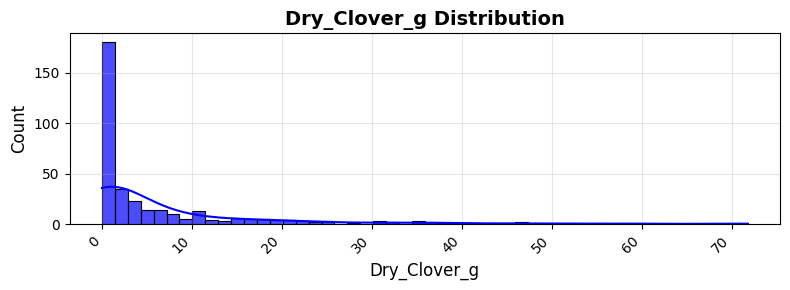

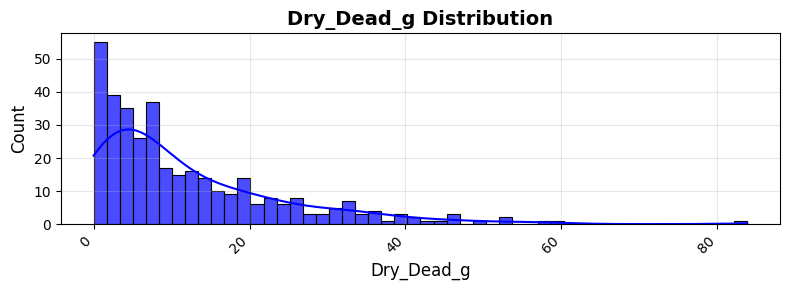

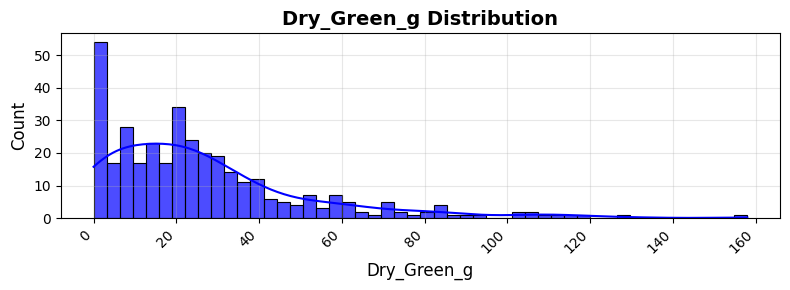

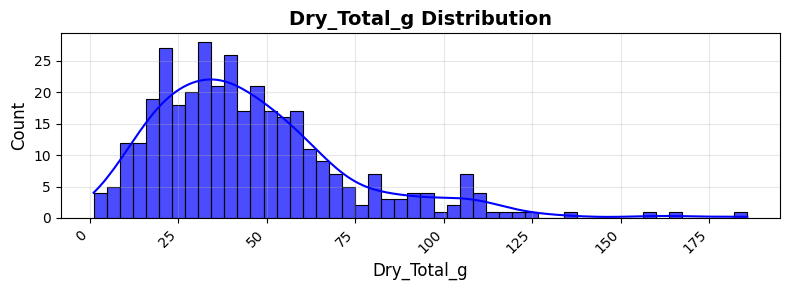

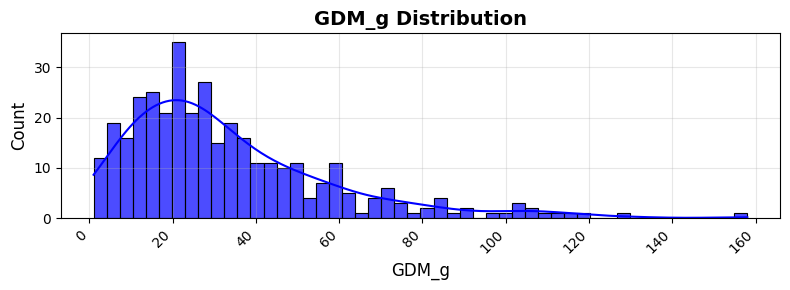

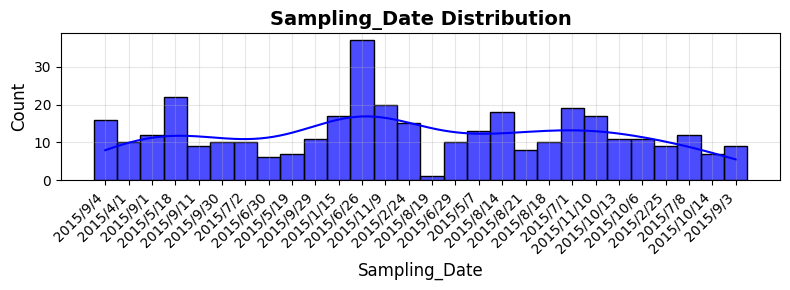

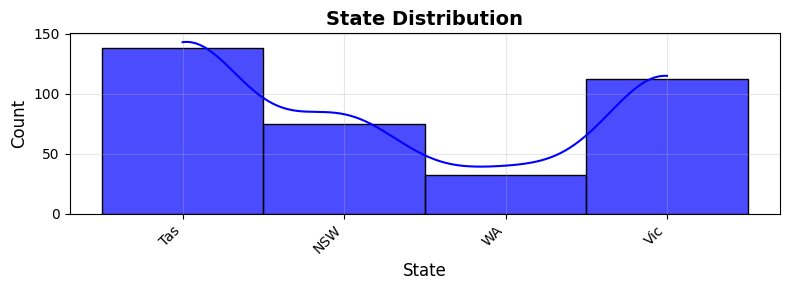

C:\Users\Liuluotu\AppData\Local\Temp\ipykernel_43336\3733516050.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout() # Adjust layout to prevent overlap


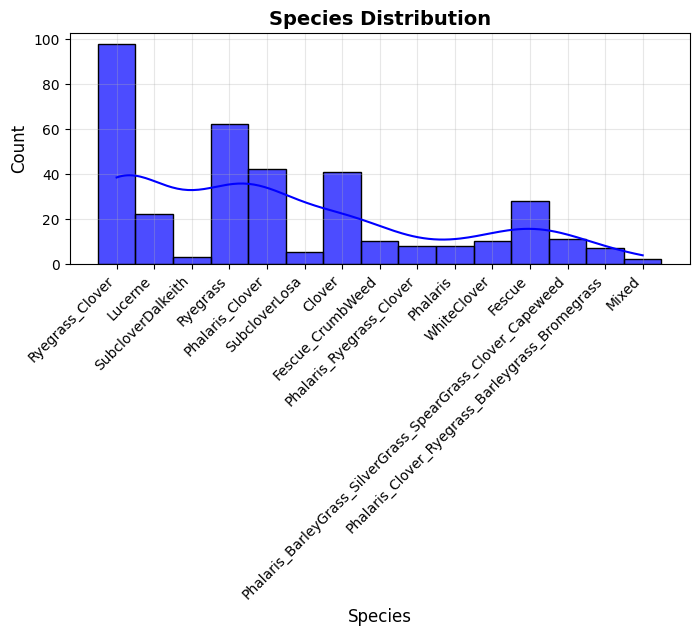

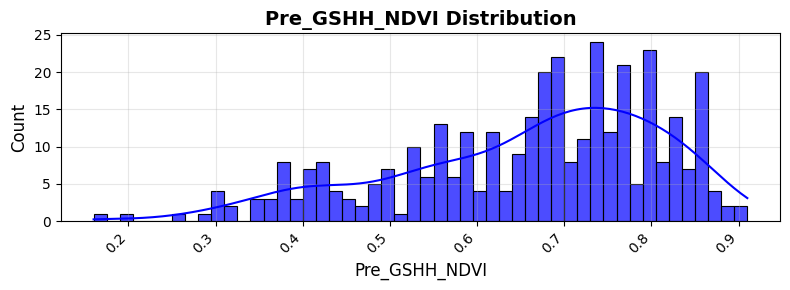

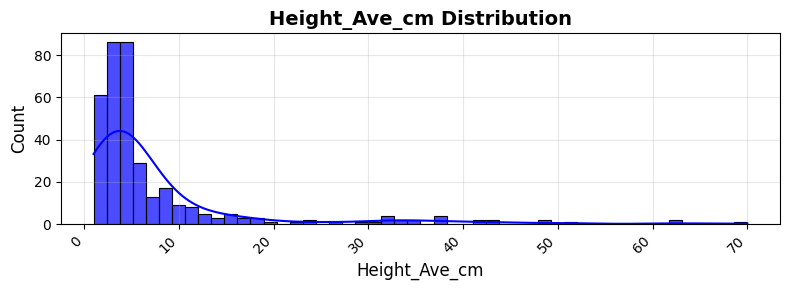

In [8]:
import seaborn as sns

# Exclude non-numeric or identifier columns from histogram plotting
cols_to_plot = [col for col in TARGET_COLS if col not in ['sample_id', 'image_path']]

for col in cols_to_plot:
    plt.figure(figsize=(8, 3)) # Create a new figure for each histogram
    sns.histplot(df[col].dropna(), bins=50, kde=True, color='blue', edgecolor='black', alpha=0.7)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.title(f'{col} Distribution', fontsize=14, fontweight='bold')
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45, ha="right") # Rotate x-axis labels
    plt.tight_layout() # Adjust layout to prevent overlap
    plt.show()

C:\Users\Liuluotu\AppData\Local\Temp\ipykernel_43336\1676717336.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_target[ALL_TARGET_COLS] = np.log1p(df_target[ALL_TARGET_COLS])


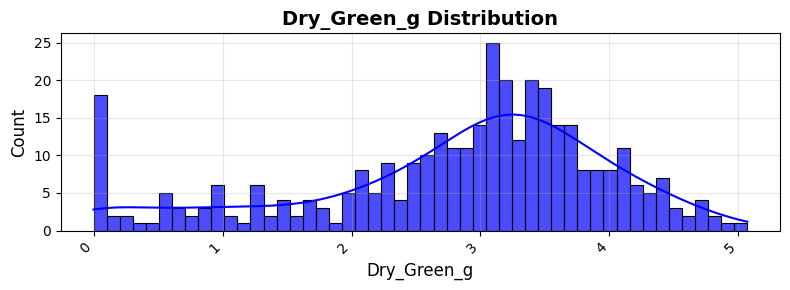

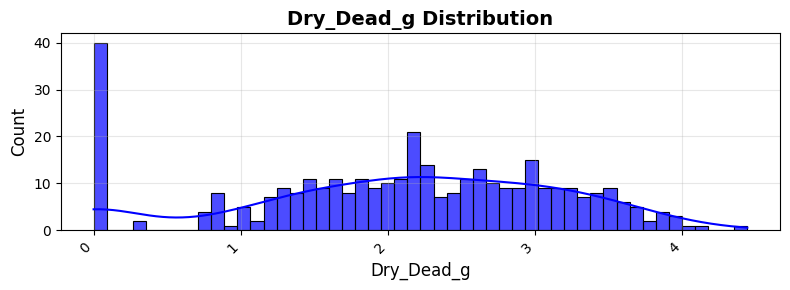

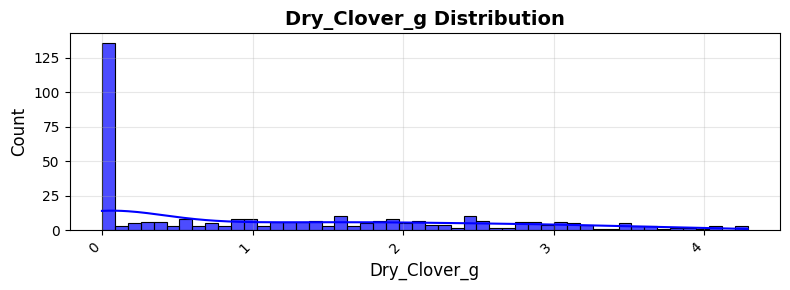

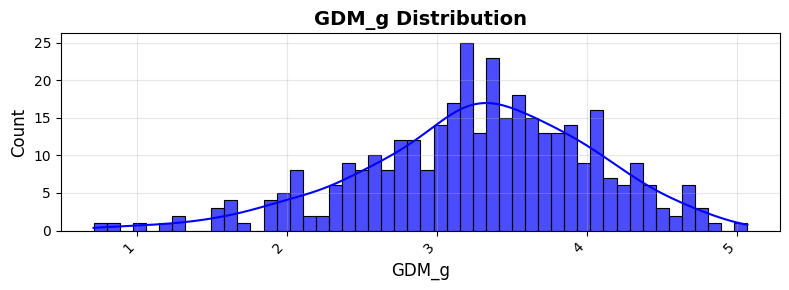

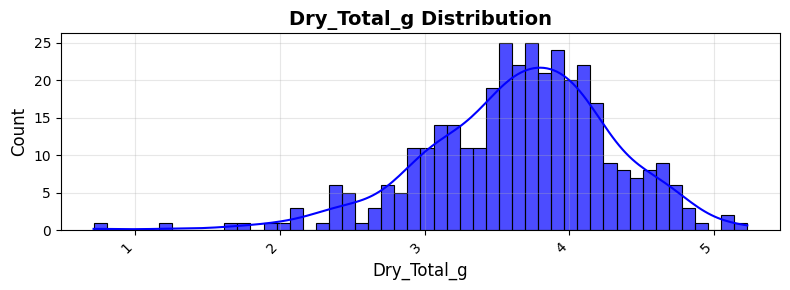

In [14]:

ALL_TARGET_COLS = ['Dry_Green_g','Dry_Dead_g','Dry_Clover_g','GDM_g','Dry_Total_g']

df_target = df[ALL_TARGET_COLS]
# 对目标列应用log(x + 1)变换
df_target[ALL_TARGET_COLS] = np.log1p(df_target[ALL_TARGET_COLS])
df_target

for col in ALL_TARGET_COLS:
    plt.figure(figsize=(8, 3)) # Create a new figure for each histogram
    sns.histplot(df_target[col].dropna(), bins=50, kde=True, color='blue', edgecolor='black', alpha=0.7)
    plt.xlabel(col, fontsize=12)
    plt.ylabel('Count', fontsize=12)
    plt.title(f'{col} Distribution', fontsize=14, fontweight='bold')
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45, ha="right") # Rotate x-axis labels
    plt.tight_layout() # Adjust layout to prevent overlap
    plt.show()



In [15]:
df_target.describe()

,Dry_Green_g,Dry_Dead_g,Dry_Clover_g,GDM_g,Dry_Total_g
count,357.000000,357.000000,357.000000,357.000000,357.000000
mean,2.807202,2.087335,1.174004,3.273909,3.651970
std,1.186633,1.076524,1.246057,0.763890,0.643380
min,0.000000,0.000000,0.000000,0.712950,0.712950
25%,2.282382,1.435085,0.000000,2.834747,3.268485
50%,3.081910,2.195100,0.885213,3.336061,3.720862
75%,3.585833,2.925192,2.109352,3.799430,4.075501
max,5.068801,4.440775,4.287530,5.068801,5.229503


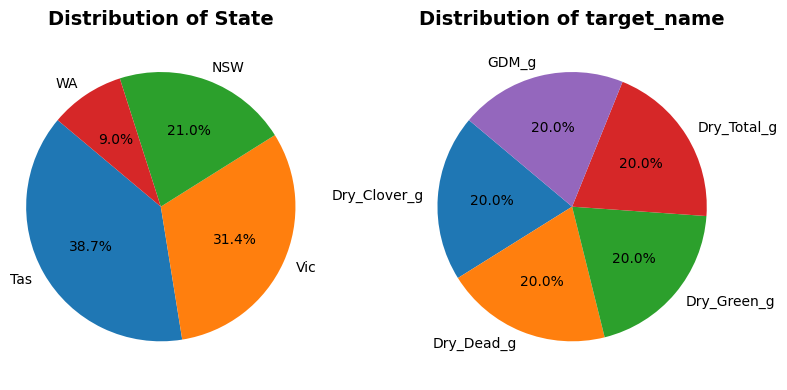

In [13]:
cols_to_plot = ['State', 'target_name']
n_rows, n_cols = 1, len(cols_to_plot)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))

# Ensure axes is an array even for a single subplot
axes = axes.flatten()

for ax, col in zip(axes, cols_to_plot):
    counts = df[col].value_counts()
    ax.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=140)
    ax.set_title(f'Distribution of {col}', fontsize=14, fontweight='bold')
    ax.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

plt.tight_layout()
plt.show()

In [14]:
# Convert 'Sampling_Date' to datetime objects
df['Sampling_Date'] = pd.to_datetime(df['Sampling_Date'])

# Extract the day of the year
df['Day_of_Year'] = df['Sampling_Date'].dt.dayofyear

# Calculate the correlation between 'target' and 'Day_of_Year'
correlation = df['target'].corr(df['Day_of_Year'])

print(f"The correlation between 'target' and 'Day_of_Year' is: {correlation}")

The correlation between 'target' and 'Day_of_Year' is: -0.06195957047064342


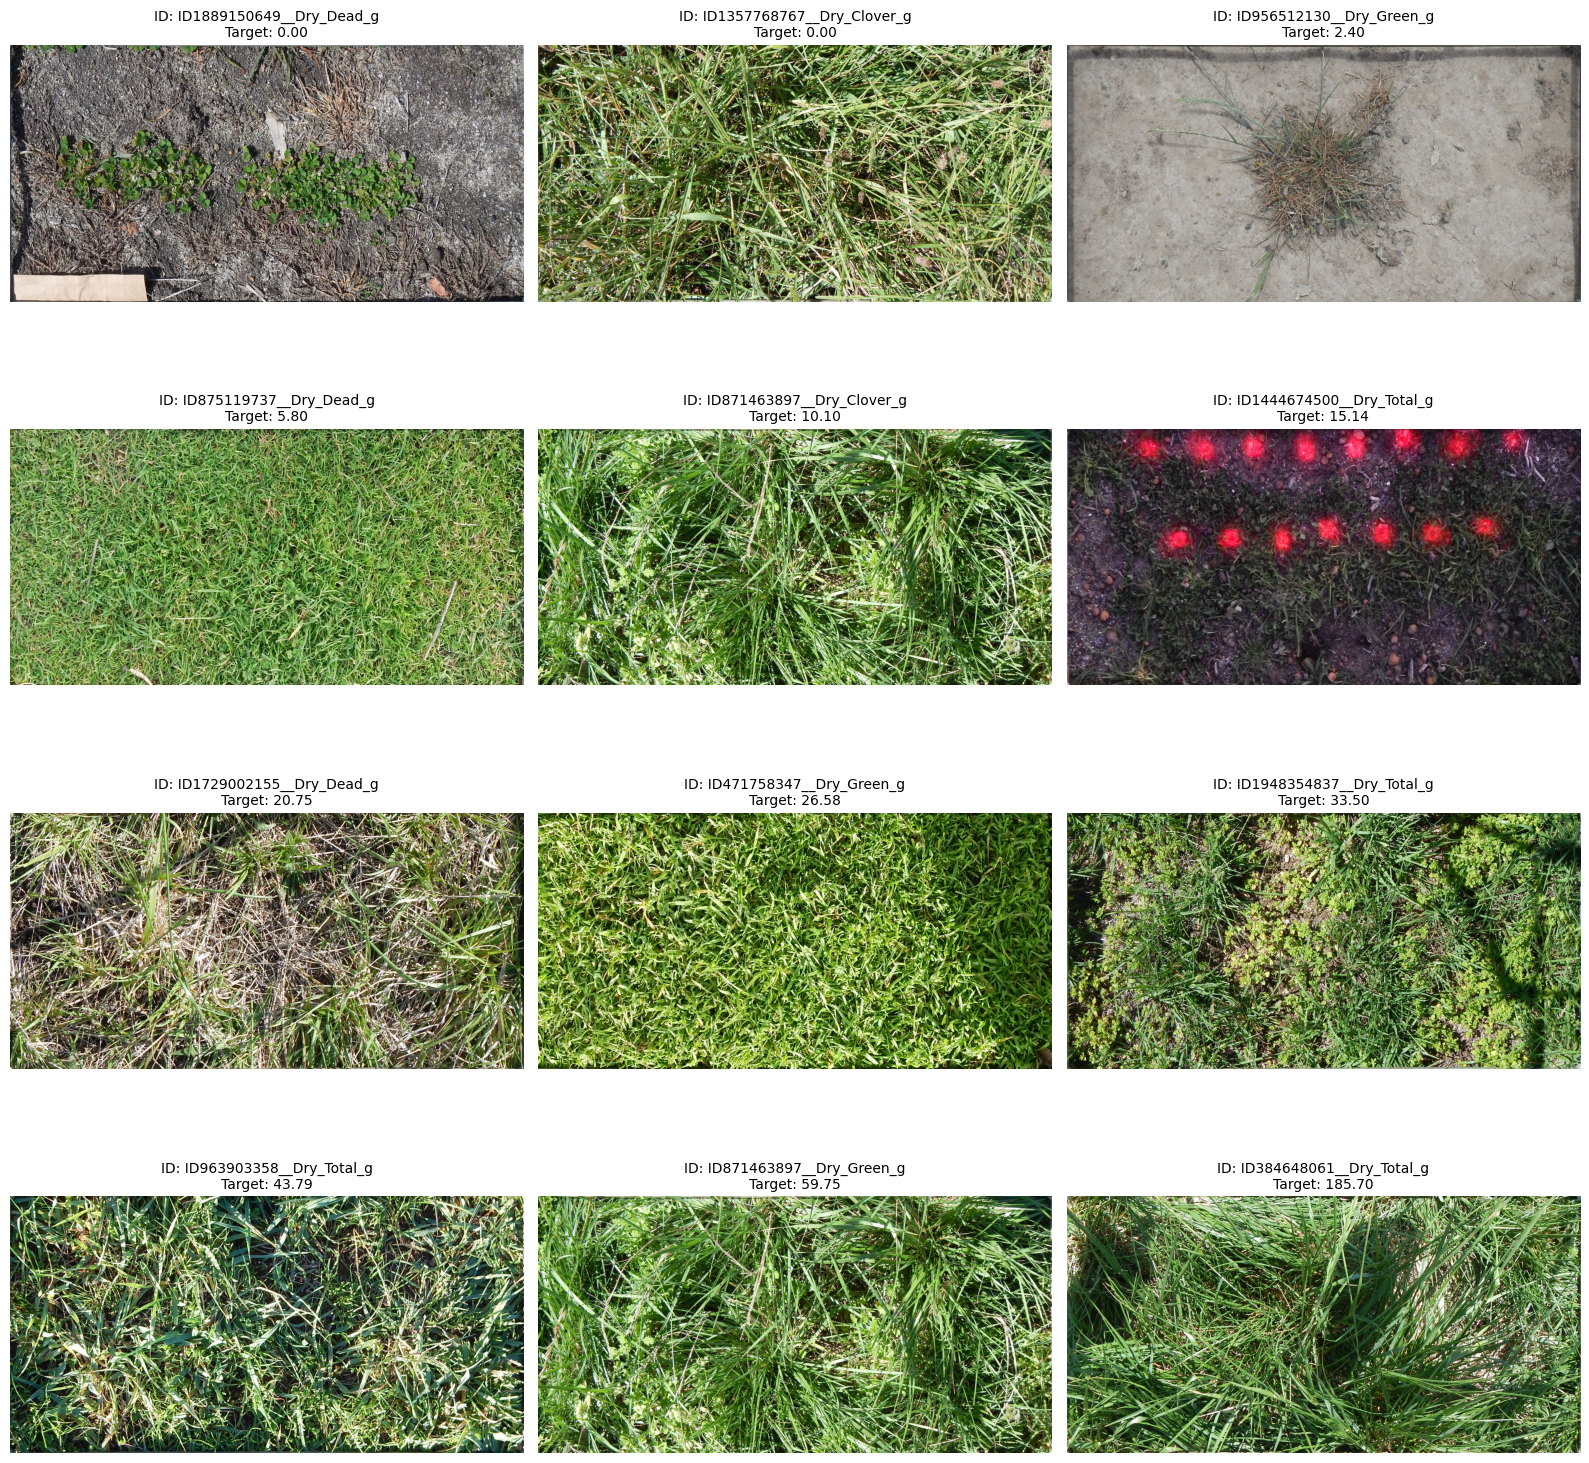

In [16]:
def show_images(df_sample, n=12, path_img=PATH_DATA):
    """Displays a linear sampling of images sorted by target value."""

    # Sort the DataFrame by the 'target' column
    df_sorted = df_sample.sort_values(by='target').reset_index(drop=True)

    # Perform linear sampling
    indices_to_show = np.linspace(0, len(df_sorted) - 1, n, dtype=int)
    df_to_show = df_sorted.iloc[indices_to_show]

    # Determine the number of rows and columns for subplots
    n_cols = 3  # You can adjust this number
    n_rows = (n + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
    axes = axes.flatten()

    # Remove unused subplots if any
    for i in range(n, len(axes)):
        fig.delaxes(axes[i])

    for i, (idx, row) in enumerate(df_to_show.iterrows()):
        # Use image_path directly (includes train/ID....jpg)
        img_path = os.path.join(path_img, row['image_path'])

        if os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB')
            axes[i].imshow(img)
            # Include the target value in the title
            title = f"ID: {row['sample_id']}\nTarget: {row['target']:.2f}"
            axes[i].set_title(title, fontsize=10)
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# Example usage: Show 12 images linearly sampled based on target value
show_images(df, n=12)


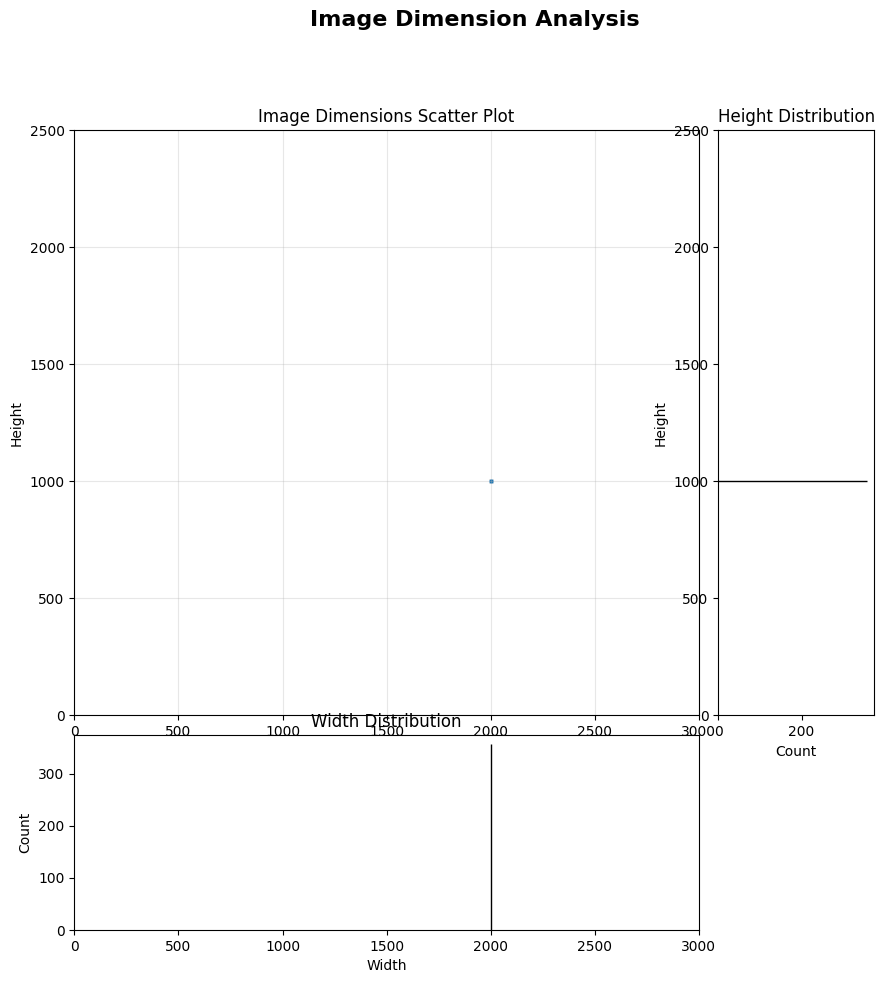

In [17]:
import os
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Collect image sizes
image_sizes = []
image_dir = os.path.join(PATH_DATA, 'train') # Assuming 'train' directory contains images

for img_file in os.listdir(image_dir):
    img_path = os.path.join(image_dir, img_file)
    with Image.open(img_path) as img:
        image_sizes.append({'width': img.width, 'height': img.height})

image_sizes_df = pd.DataFrame(image_sizes)

# Create a scatter plot and histograms for image dimensions
fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(3, 1), # Adjusted height_ratios
                      left=0.1, right=0.9, bottom=0.1, top=0.9,
                      wspace=0.05, hspace=0.05)

ax_scatter = fig.add_subplot(gs[0, 0])
ax_histy = fig.add_subplot(gs[0, 1]) # Removed sharey
ax_histx = fig.add_subplot(gs[1, 0]) # Removed sharex
# Scatter plot
sns.scatterplot(data=image_sizes_df, x='width', y='height', ax=ax_scatter, alpha=0.6, s=10)
ax_scatter.set_xlabel('Width')
ax_scatter.set_ylabel('Height')
ax_scatter.set_title('Image Dimensions Scatter Plot')
ax_scatter.grid(True, alpha=0.3) # Add grid to scatter plot
ax_scatter.set_xlim(0, 3000) # Adjusted x-axis limits to include 2000
ax_scatter.set_ylim(0, 2500) # Adjusted y-axis limits to include 1000


# Histograms
sns.histplot(data=image_sizes_df, x='width', ax=ax_histx, bins=1, kde=False) # Adjusted bins for single value
ax_histx.set_title('Width Distribution')
ax_histx.set_xlabel('Width')
ax_histx.set_xlim(0, 3000) # Adjusted x-axis limits to include 2000


sns.histplot(data=image_sizes_df, y='height', ax=ax_histy, bins=1, kde=False) # Adjusted bins for single value
ax_histy.set_title('Height Distribution')
ax_histy.set_ylabel('Height')
ax_histy.set_ylim(0, 2500) # Adjusted y-axis limits to include 1000


plt.suptitle('Image Dimension Analysis', fontsize=16, fontweight='bold', y=1.02)
plt.show()

In [14]:
cat_cols = ['Sampling_Date', 'State', 'Species', 'target_name']
num_cols = ['Pre_GSHH_NDVI', 'Height_Ave_cm']

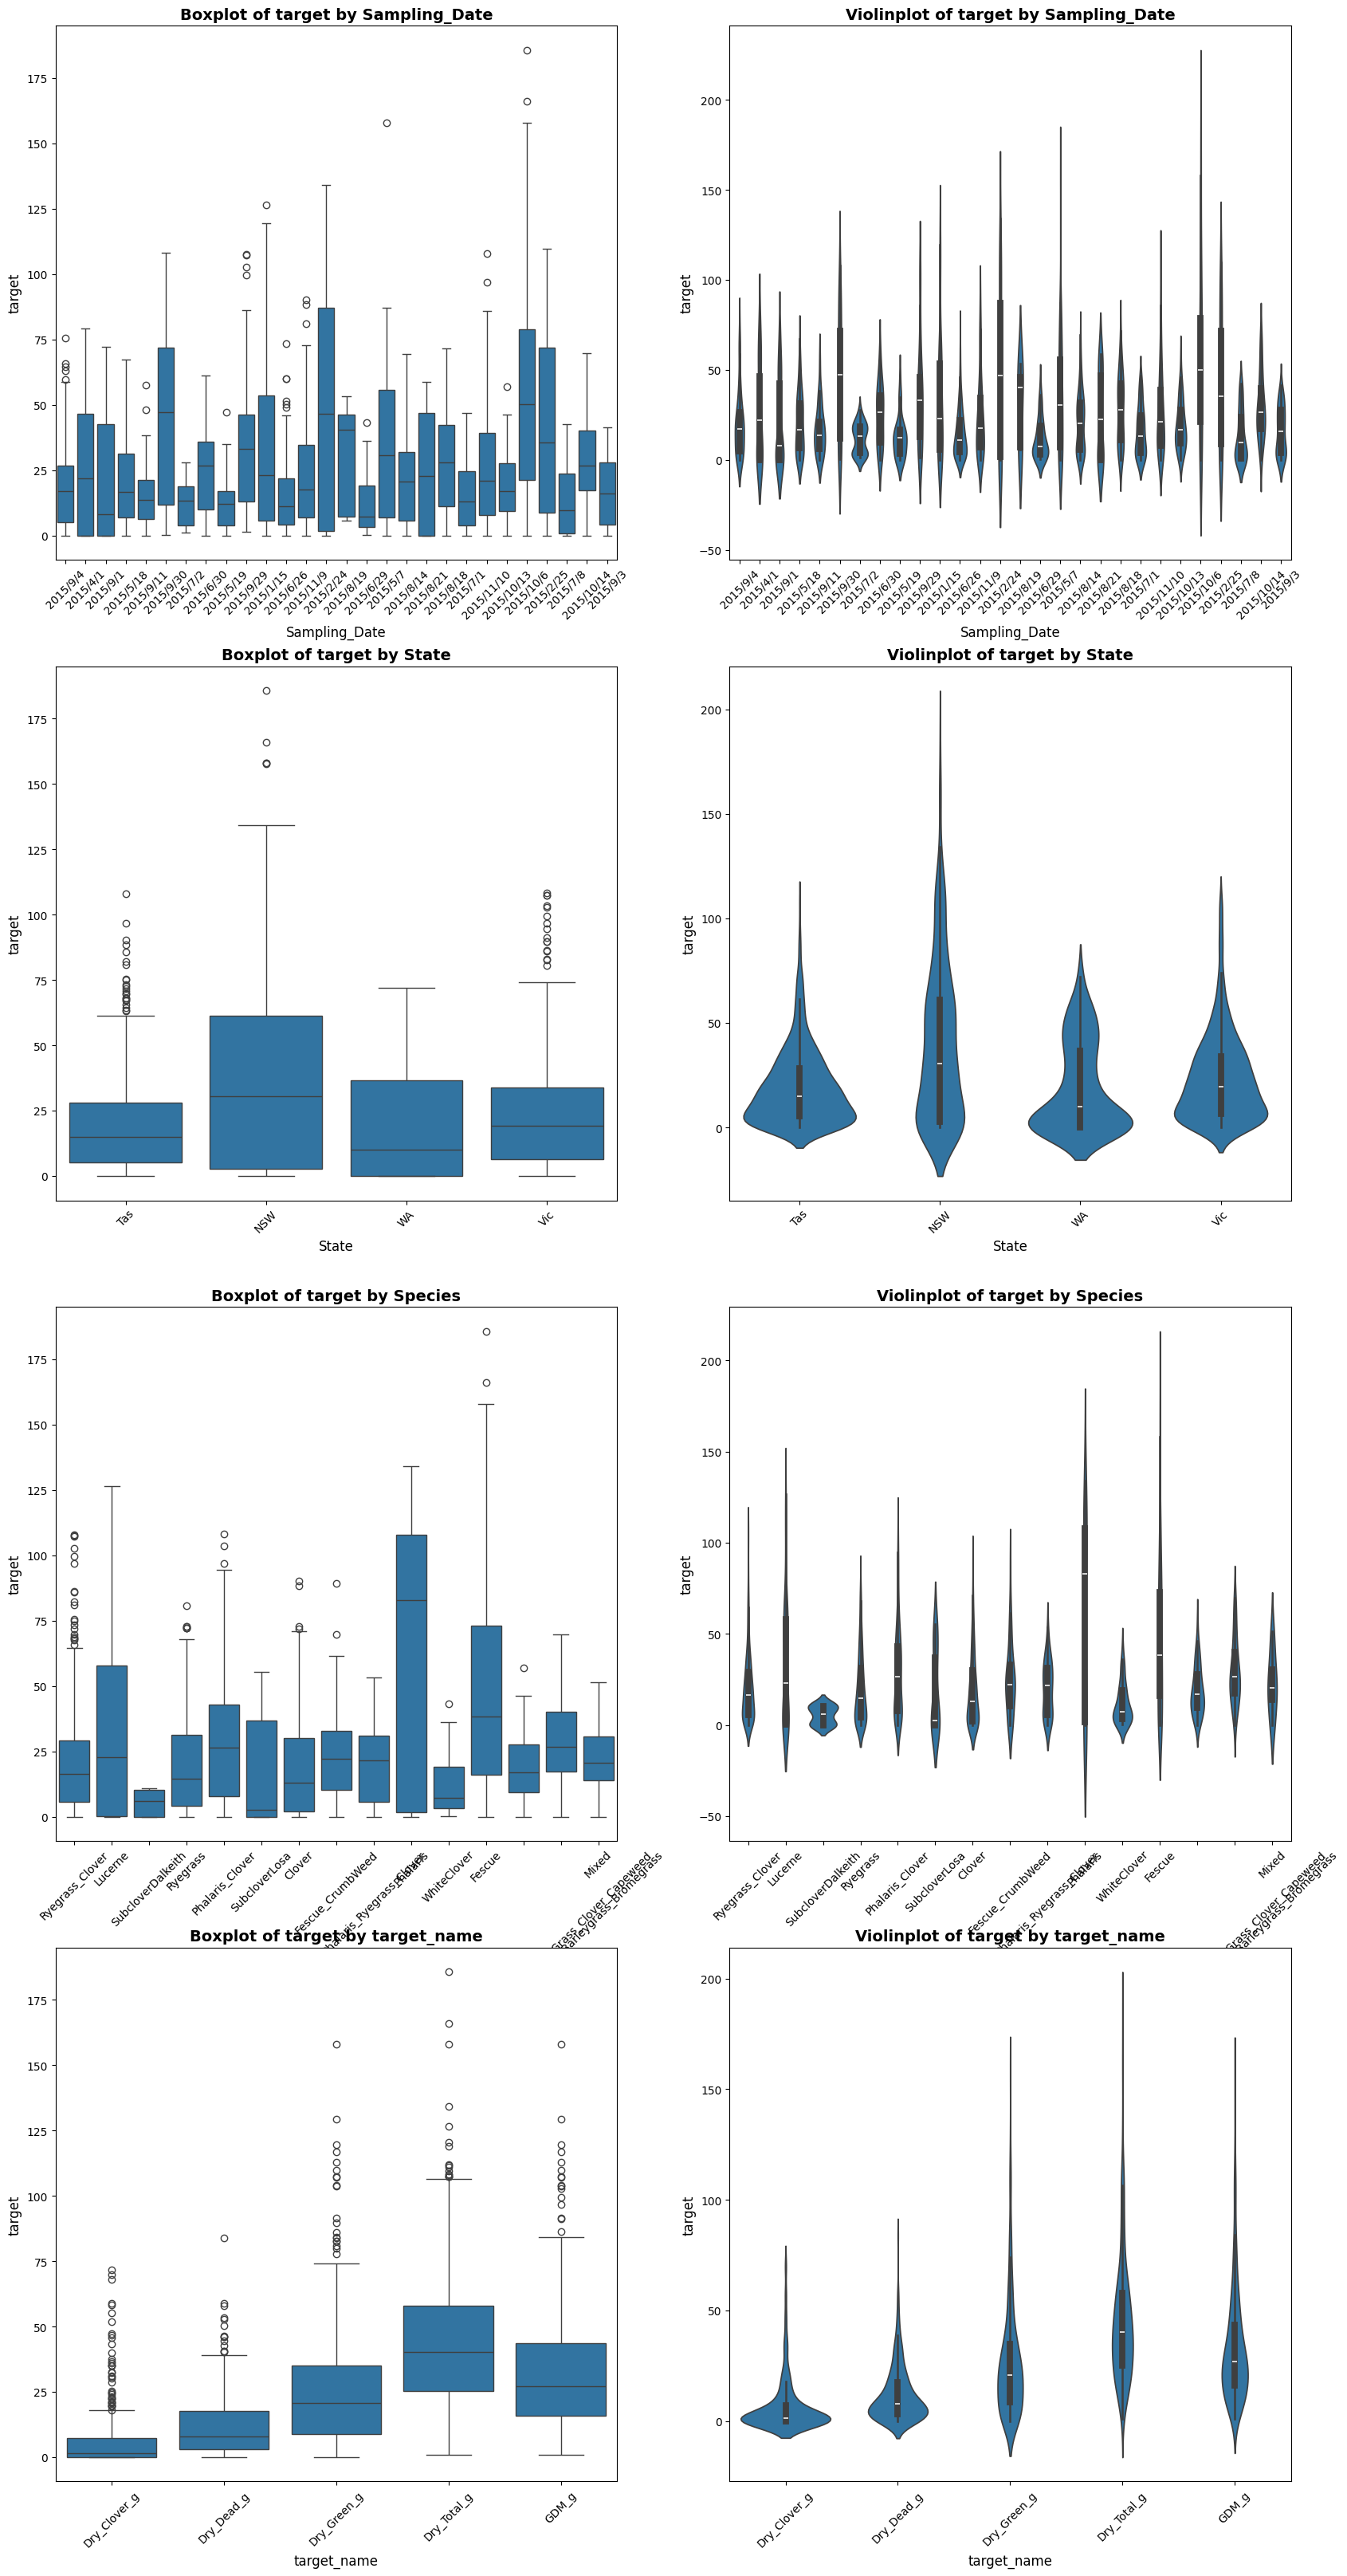

In [ ]:
import seaborn as sns


fig, ax = plt.subplots(len(cat_cols), 2, figsize=(20, 10 * len(cat_cols)))

for fold, col in enumerate(cat_cols):
    sns.boxplot(x=col, y='target', data=df, ax=ax[fold, 0])
    sns.violinplot(x=col, y='target', data=df, ax=ax[fold, 1])
    ax[fold, 0].set_title(f'Boxplot of target by {col}', fontsize=14, fontweight='bold')
    ax[fold, 0].set_xlabel(col, fontsize=12)
    ax[fold, 0].set_ylabel('target', fontsize=12)
    ax[fold, 1].set_title(f'Violinplot of target by {col}', fontsize=14, fontweight='bold')
    ax[fold, 1].set_xlabel(col, fontsize=12)
    ax[fold, 1].set_ylabel('target', fontsize=12)
    for tick in ax[fold, 0].get_xticklabels():
        tick.set_rotation(45)
    for tick in ax[fold, 1].get_xticklabels():
        tick.set_rotation(45)



Number of unique imgs: 357
Number of imgs with 5 samples: 357


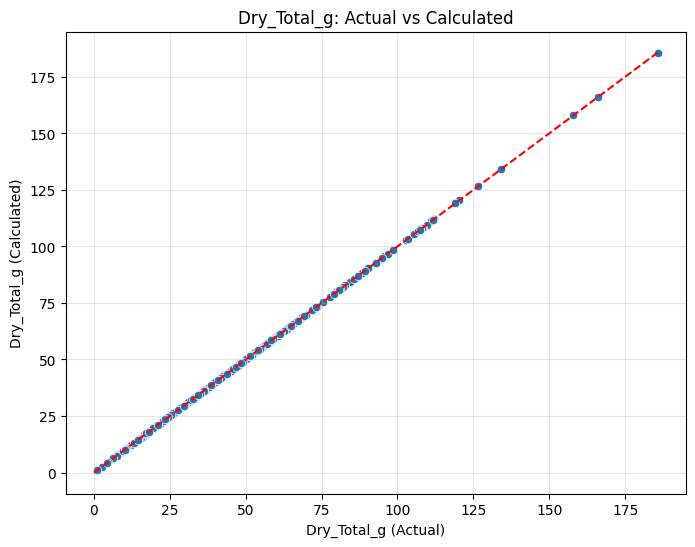

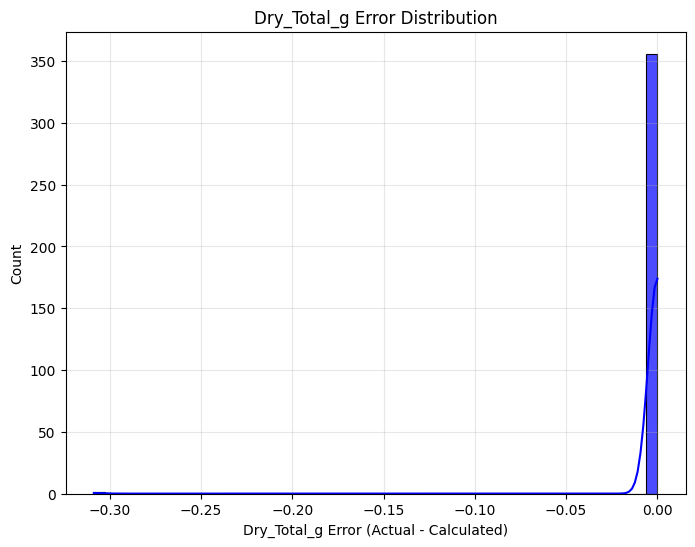

Dry_Total_g Error: Mean=-0.0008655462184871367, Std=0.016343440616208276, 占比mean=-0.00%, 占比std=0.06%


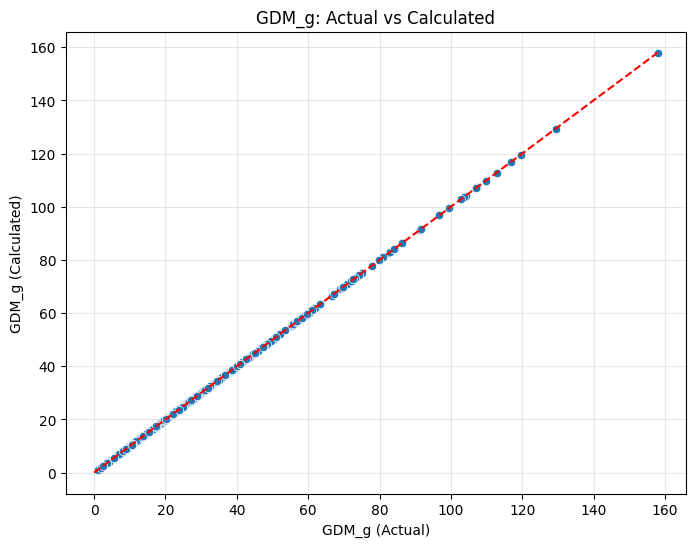

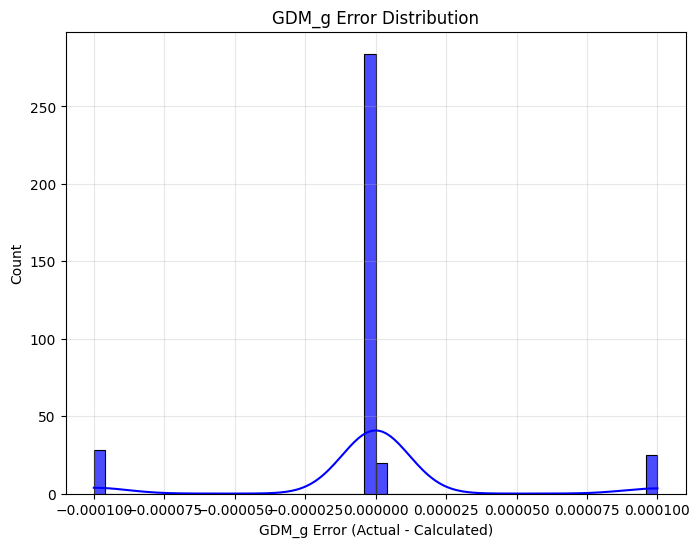

GDM_g Error: Mean=-8.40336134239108e-07, Std=3.8575327561918795e-05, 占比mean=-0.00%, 占比std=0.00%


In [35]:
# 分析需要预测的各个量之间的关系
"""
Dry_Clover_g: 干燥的三叶草生物量
Dry_Dead_g: 干燥的枯死物质
Dry_Green_g: 干燥的绿色植被（不包括三叶草）
Dry_Total_g: 总干生物量
GDM_g: 绿色干物质
"""

df["id"] = df['sample_id'].apply(lambda x: x.split('_')[0])
print(f"Number of unique imgs: {df['id'].nunique()}")
print(f"Number of imgs with 5 samples: {(df['id'].value_counts() == 5).sum()}")

dry_clover_idx = df['target_name'] == 'Dry_Clover_g'
dry_clover = df[dry_clover_idx].reset_index(drop=True)
dry_dead_idx = df['target_name'] == 'Dry_Dead_g'
dry_dead = df[dry_dead_idx].reset_index(drop=True)
dry_green_idx = df['target_name'] == 'Dry_Green_g'
dry_green = df[dry_green_idx].reset_index(drop=True)
dry_total_idx = df['target_name'] == 'Dry_Total_g'
dry_total = df[dry_total_idx].reset_index(drop=True)
gmd_idx = df['target_name'] == 'GDM_g' 
gmd = df[gmd_idx].reset_index(drop=True)


# 绿色干物质（不包括三叶草）+干燥的枯死物质+干燥的三叶草生物量 ≈ 总干生物量
dry_total_calculated = dry_clover['target'] + dry_dead['target'] + dry_green['target']
plt.figure(figsize=(8, 6))
sns.scatterplot(x=dry_total['target'], y=dry_total_calculated)
plt.xlabel('Dry_Total_g (Actual)')
plt.ylabel('Dry_Total_g (Calculated)')
plt.title('Dry_Total_g: Actual vs Calculated')
plt.plot([0, dry_total['target'].max()], [0, dry_total['target'].max()], 'r--')  # y=x line
plt.grid(alpha=0.3)
plt.show()
# 误差大小
dry_total_error = dry_total['target'] - dry_total_calculated
plt.figure(figsize=(8, 6))
sns.histplot(dry_total_error, bins=50, kde=True, color='blue', edgecolor='black', alpha=0.7)
plt.xlabel('Dry_Total_g Error (Actual - Calculated)')
plt.title('Dry_Total_g Error Distribution')
plt.grid(alpha=0.3)
plt.show()
print(f"Dry_Total_g Error: Mean={dry_total_error.mean()}, Std={dry_total_error.std()}, 占比mean={dry_total_error.mean()/dry_total['target'].mean()*100:.2f}%, 占比std={dry_total_error.std()/dry_total['target'].std()*100:.2f}%")

# 绿色干物质（不包括三叶草）+干燥的三叶草生物量 ≈ 绿色干物质
gmd_calculated = dry_green['target'] + dry_clover['target']
plt.figure(figsize=(8, 6))
sns.scatterplot(x=gmd['target'], y=gmd_calculated)
plt.xlabel('GDM_g (Actual)')
plt.ylabel('GDM_g (Calculated)')
plt.title('GDM_g: Actual vs Calculated')
plt.plot([0, gmd['target'].max()], [0, gmd['target'].max()], 'r--')  # y=x line
plt.grid(alpha=0.3)
plt.show()
# 误差大小
gmd_error = gmd['target'] - gmd_calculated
plt.figure(figsize=(8, 6))
sns.histplot(gmd_error, bins=50, kde=True, color='blue', edgecolor='black', alpha=0.7)
plt.xlabel('GDM_g Error (Actual - Calculated)')
plt.title('GDM_g Error Distribution')
plt.grid(alpha=0.3)
plt.show()
print(f"GDM_g Error: Mean={gmd_error.mean()}, Std={gmd_error.std()}, 占比mean={gmd_error.mean()/gmd['target'].mean()*100:.2f}%, 占比std={gmd_error.std()/gmd['target'].std()*100:.2f}%")


